# EDA 08 (tuning): khoảng trống xảy ra lúc nào, hai đầu có gần nhau không

Khi GPS ngừng ghi thì ngừng lúc nào, bao lâu, hai đầu có gần nhau không. Notebook không chọn trước khung giờ hay định nghĩa "qua đêm".

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | Khoảng trống xảy ra lúc nào, dài bao lâu, hai đầu có gần nhau không? | Nguồn phụ để suy ra home/office (A12), ngưỡng khoảng trống (A7) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục đánh số riêng trong từng notebook (bảng mục và notebook ở README).

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 03 mục 2. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [7]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.val_users()   # nhóm validation (D17); KHÔNG đặt None ở notebook tuning: sẽ đọc cả nhóm test (D17)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['coverage'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
gaps = R.gaps
print(f"{len(users)} user, {len(files):,} file")

[20/115] đã đọc tới user 033 (3 giây)
[40/115] đã đọc tới user 063 (5 giây)
[60/115] đã đọc tới user 102 (6 giây)
[80/115] đã đọc tới user 132 (8 giây)
[100/115] đã đọc tới user 163 (12 giây)
[115/115] đã đọc tới user 180 (13 giây)
115 user, 12,376 file


## 1. Khoảng trống: xảy ra lúc nào, dài bao lâu, hai đầu có gần nhau không

**Câu hỏi:** khi GPS ngừng ghi, khoảng trống thường bắt đầu và kết thúc lúc mấy giờ (địa phương), kéo dài bao lâu, và điểm trước khi ngừng với điểm sau khi ghi lại cách nhau bao xa? Nếu có một nhóm khoảng trống bắt đầu buổi tối, kết thúc buổi sáng và hai đầu gần nhau, đó là dấu hiệu user tắt máy ở cùng một chỗ. Notebook không định nghĩa trước thế nào là "qua đêm".

`gaps.csv` lưu mọi bước dài hơn mốc nhỏ nhất (`GAP_MARKS_MIN[0]` = 5 phút, dài hơn khoảng lấy mẫu điển hình của mọi user ở mục 1 (notebook 02)), chỉ xét bước mà hai đầu có timestamp hợp lệ.

- `start_local`, `end_local`: giờ địa phương của điểm trước và sau khoảng trống.
- `gap_h`: độ dài (giờ). `dist_m`: khoảng cách giữa hai đầu (mét).


Khoảng trống > 5 phút: 35,444 ở 115 user


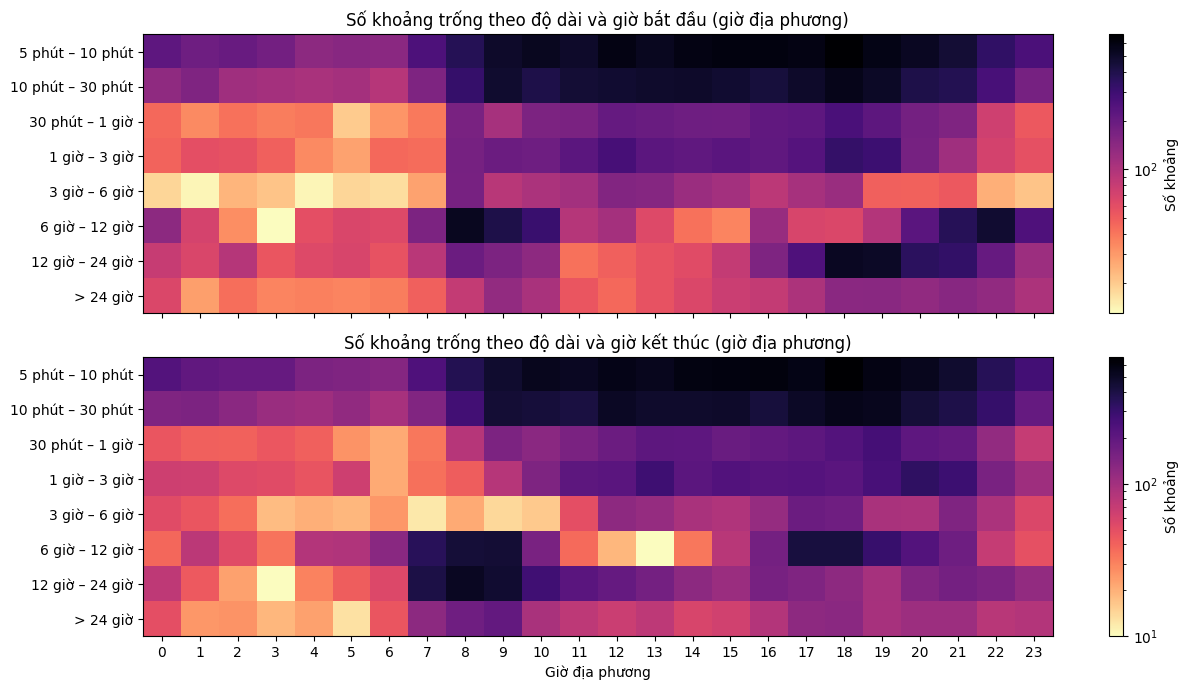

In [8]:
print(f"Khoảng trống > {GAP_MARKS_MIN[0]} phút: {len(gaps):,} ở {gaps['user'].nunique()} user")
gaps["start_hour"] = gaps["start_local"].dt.hour
gaps["end_hour"] = gaps["end_local"].dt.hour
edges = GAP_MARKS_MIN + [np.inf]
dur_labels = [f"{fmt_s(a * 60)} – {fmt_s(b * 60)}" if np.isfinite(b) else f"> {fmt_s(a * 60)}"
              for a, b in zip(edges[:-1], edges[1:])]
gaps["dur"] = pd.cut(gaps["gap_h"] * 60, bins=edges, labels=dur_labels)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, col, title in ((axes[0], "start_hour", "giờ bắt đầu"), (axes[1], "end_hour", "giờ kết thúc")):
    ct = pd.crosstab(gaps["dur"], gaps[col]).reindex(index=dur_labels, columns=range(24), fill_value=0)
    im = ax.imshow(np.ma.masked_equal(ct.to_numpy(), 0), aspect="auto", cmap="magma_r", norm=LogNorm())
    ax.set_yticks(range(len(dur_labels))); ax.set_yticklabels(dur_labels)
    ax.set_title(f"Số khoảng trống theo độ dài và {title} (giờ địa phương)")
    plt.colorbar(im, ax=ax, label="Số khoảng")
axes[1].set_xticks(range(24)); axes[1].set_xlabel("Giờ địa phương")
plt.tight_layout()
plt.show()


Khoảng cách giữa hai đầu khoảng trống, theo độ dài. Các mức 100/200/500/1.000 m chỉ là mốc mô tả.


,số_khoảng,số_user,dist_trung_vị_m,≤ 100 m (%),≤ 200 m (%),≤ 500 m (%),≤ 1000 m (%)
dur,,,,,,,
5 phút – 10 phút,9695,110,28.3,79.4,83.9,88.5,91.0
10 phút – 30 phút,7816,109,29.3,68.8,74.8,80.5,83.0
30 phút – 1 giờ,3039,98,87.5,51.8,62.1,72.0,76.2
1 giờ – 3 giờ,3584,105,139.6,43.1,58.1,73.6,81.1
3 giờ – 6 giờ,1684,92,328.8,25.6,39.3,61.0,72.1
6 giờ – 12 giờ,3881,93,283.2,24.3,40.0,64.4,78.0
12 giờ – 24 giờ,3812,102,452.7,15.6,28.5,52.4,65.6
> 24 giờ,1933,105,1157.0,10.0,19.1,37.2,48.6


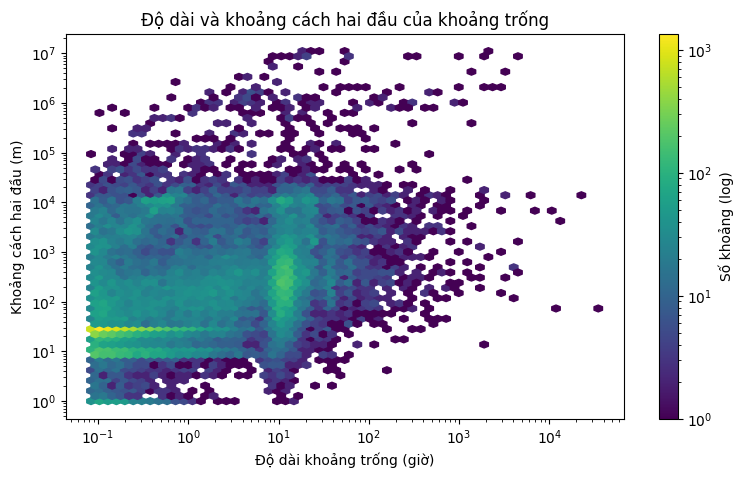

In [9]:
g = gaps.groupby("dur", observed=False)
tb = g.agg(số_khoảng=("dist_m", "size"), số_user=("user", "nunique"), dist_trung_vị_m=("dist_m", "median"))
for r in (100, 200, 500, 1000):
    tb[f"≤ {r} m (%)"] = g["dist_m"].apply(lambda s, r=r: (s <= r).mean() * 100 if len(s) else np.nan)
display(tb.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(gaps["gap_h"], gaps["dist_m"].clip(lower=1), xscale="log", yscale="log",
               gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax.set_xlabel("Độ dài khoảng trống (giờ)"); ax.set_ylabel("Khoảng cách hai đầu (m)")
ax.set_title("Độ dài và khoảng cách hai đầu của khoảng trống")
plt.colorbar(hb, ax=ax, label="Số khoảng (log)")
plt.show()
